Memuat dataset Data.xlsx...
Total Baris Data setelah dibersihkan: 1000
Total Kolom Data: 9

5 Baris Pertama Dataset:


,Usia,Jenis Kelamin,Status Pasien,Jenis Kunjungan,Kategori Keluhan,Rujukan,Janji Temu,Poli Tujuan,Kebutuhan Pelayanan (Target)
0,7,Perempuan,Baru,Berobat,Pernapasan,Tidak,Tidak,Anak,Konsultasi
1,14,Laki-laki,Lama,Pemeriksaan,Sakit Gigi,Tidak,Ya,Gigi,Konsultasi + Tindakan
2,72,Perempuan,Baru,Berobat,Pemeriksaan Umum,Tidak,Tidak,Lansia,Laboratorium
3,12,Perempuan,Baru,Berobat,Sakit Gigi,Tidak,Tidak,Gigi,Konsultasi + Tindakan
4,6,Laki-laki,Baru,Berobat,Demam,Tidak,Tidak,Anak,Konsultasi


Model Decision Tree Classifier Berhasil Dilatih!
AKURASI MODEL DECISION TREE: 87.50%

Laporan Klasifikasi Lengkap:
                          precision    recall  f1-score   support

              Konsultasi       0.93      0.71      0.80        55
Konsultasi + Pemeriksaan       0.98      0.92      0.95        61
   Konsultasi + Tindakan       0.60      0.89      0.72        36
            Laboratorium       1.00      1.00      1.00        48

                accuracy                           0.88       200
               macro avg       0.88      0.88      0.87       200
            weighted avg       0.90      0.88      0.88       200



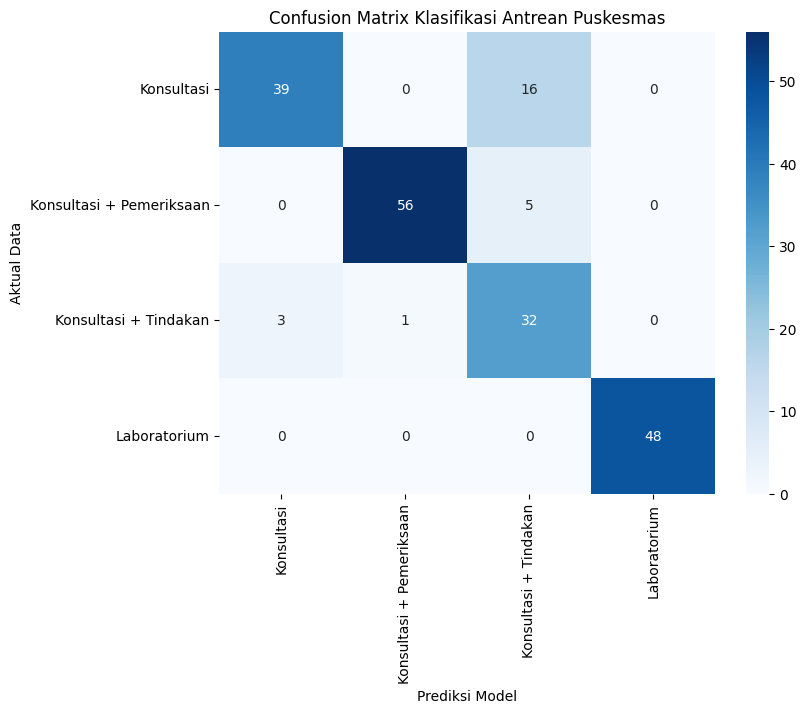


File 'model_antrean_puskesmas.pkl' berhasil dibuat!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

# 1. Memuat dataset langsung dari file yang sudah ada di Colab
print("Memuat dataset Data.xlsx...")
df = pd.read_excel('Data.xlsx')
df.columns = [str(c).strip() for c in df.columns]

# Hapus baris yang memiliki data kosong (NaN) agar model tidak error
df = df.dropna()

print(f"Total Baris Data setelah dibersihkan: {df.shape[0]}")
print(f"Total Kolom Data: {df.shape[1]}")
print("\n5 Baris Pertama Dataset:")
display(df.head())

# 2. Tentukan Kolom Target (Output)
target_col = 'Kebutuhan Pelayanan (Target)'
if target_col not in df.columns:
    for c in df.columns:
        if 'kebutuhan' in c.lower() or 'target' in c.lower():
            target_col = c
            break

# 3. Pisahkan Fitur (X) dan Target (y)
X = df.drop(columns=[target_col])
y = df[target_col]

# Abaikan kolom nomor/ID jika ada
id_cols = [c for c in X.columns if c.lower() in ['no', 'no.', 'id', 'id_pasien', 'unnamed: 0']]
if id_cols:
    X = X.drop(columns=id_cols)

# 4. Label Encoding
label_encoders = {}
X_encoded = X.copy()

for col in X_encoded.columns:
    if X_encoded[col].dtype == 'object' or str(X_encoded[col].dtype) == 'category':
        le = LabelEncoder()
        X_encoded[col] = le.fit_transform(X_encoded[col].astype(str))
        label_encoders[col] = le

target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(y.astype(str))
target_classes = target_encoder.classes_

# 5. Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.2, random_state=42
)

# 6. Melatih Model Decision Tree
dt_model = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)

print("Model Decision Tree Classifier Berhasil Dilatih!")

# 7. Evaluasi Model
y_pred = dt_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("="*60)
print(f"AKURASI MODEL DECISION TREE: {accuracy * 100:.2f}%")
print("="*60)
print("\nLaporan Klasifikasi Lengkap:")
print(classification_report(y_test, y_pred, target_names=target_classes, zero_division=0))

# 8. Visualisasi Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_classes, yticklabels=target_classes)
plt.title('Confusion Matrix Klasifikasi Antrean Puskesmas')
plt.xlabel('Prediksi Model')
plt.ylabel('Aktual Data')
plt.savefig('confusion_matrix.png', bbox_inches='tight')
plt.show()

# 9. Simpan & Download File
model_data = {
    'model': dt_model,
    'encoders': label_encoders,
    'target_encoder': target_encoder,
    'features': X.columns.tolist(),
    'accuracy': float(accuracy),
    'target_name': target_col
}

joblib.dump(model_data, 'model_antrean_puskesmas.pkl')
print("\nFile 'model_antrean_puskesmas.pkl' berhasil dibuat!")

# Download otomatis file model & gambar ke komputer/laptop
files.download('model_antrean_puskesmas.pkl')
files.download('confusion_matrix.png')